In [1]:
from langgraph.graph import StateGraph,START, END
from typing import TypedDict

In [4]:
class BatsmenState(TypedDict):
    runs:int
    balls:int
    four:int
    sixes:int
    strike_r:float
    bpb:float
    boundary_percent:float
    summary:str

In [22]:
def calculate_sr(state:BatsmenState):
    sr=(state['runs']/state['balls'])*100
    
    return {'strike_r':sr}

In [28]:
def calculate_bpb(state: BatsmenState):
    bpb = state['balls'] / (state['four'] + state['sixes'])
    return {'bpb': bpb}

In [15]:
def calculate_boundary_pr(state:BatsmenState)->BatsmenState:
    bpr=(((state['four']*4)+(state['sixes']*6))/state['runs'])*100

    return {'boundary_percent':bpr}

In [32]:
def summary(state: BatsmenState) -> dict:
    summary_text = f"""
    Strike rate is {state['strike_r']}
    Balls per boundary is {state['bpb']}
    Boundary percent is {state['boundary_percent']}
    """
    return {'summary': summary_text}

In [41]:
graph=StateGraph(BatsmenState)
graph.add_node('calculate_sr',calculate_sr)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_boundary_pr',calculate_boundary_pr)
graph.add_node('summary',summary)

graph.add_edge(START,'calculate_sr')
graph.add_edge(START,'calculate_bpb')
graph.add_edge(START,'calculate_boundary_pr')

graph.add_edge('calculate_sr','summary')
graph.add_edge('calculate_bpb','summary')
graph.add_edge('calculate_boundary_pr','summary')

graph.add_edge('summary',END)

workflow=graph.compile()

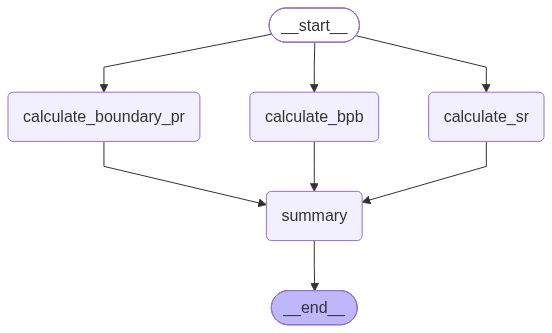

In [18]:
workflow

In [42]:
intialState={
    'runs':100,
    'balls':50,
    'four':6,
    'sixes':4
}
workflow.invoke(intialState)


{'runs': 100,
 'balls': 50,
 'four': 6,
 'sixes': 4,
 'strike_r': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0}